In [1]:
# Parameters
name      = ""
fits_path = ""

In [2]:
# Parameters
name = "FLAMES-30Dor-Ha-bin0-grid_1"
fits_path = "fits_ready/FLAMES-30Dor-Ha-bin0-grid_1.fits"


In [3]:
import time
start_time=time.time()

In [4]:
import numpy as np
import seaborn as sns
import pandas as pd
import sys
from pathlib import Path
import astropy.units as u
from matplotlib import pyplot as plt
import corner
import json
from astropy.io import fits
from lmfit.model import save_modelresult


# Add path to py_modules 
sys.path.append(str(Path().resolve() / 'py_modules')) # 1 level up = project root

#import strucfunc                   
import strucfunc
import fit_structure_function
import ci_results_compiler
import bfunc
import bplot

# Velocity Field

In [5]:
# Loading obs
hdul = fits.open(fits_path)
hdr = hdul[0].header
print(hdul.info())
print(hdr)
sb = hdul['MOM0'].data.astype(float)
vv= hdul['MOM1'].data.astype(float)

Filename: fits_ready/FLAMES-30Dor-Ha-bin0-grid_1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      23   ()      
  1  MOM0          1 ImageHDU        30   (32, 30)   float64   
  2  MOM1          1 ImageHDU        30   (32, 30)   float64   
  3  MOM2          1 ImageHDU        30   (32, 30)   float64   
  4  MASK          1 ImageHDU        30   (32, 30)   uint8   
  5  TABLE         1 BinTableHDU     35   32R x 11C   [D, D, D, D, K, D, D, D, D, D, D]   
  6  TABLE         1 BinTableHDU     35   32R x 11C   [D, D, D, D, K, D, D, D, D, D, D]   
None
SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                    8 / array data type                                NAXIS   =                    0 / number of array dimensions                     EXTEND  =                    T                                                  FILE    = 'FLAMES-30Dor-Ha-bin0' / Fits file name                       

None
SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                    8 / array data type                                NAXIS   =                    0 / number of array dimensions                     EXTEND  =                    T                                                  FILE    = 'FLAMES-30Dor-Ha-bin0' / Fits file name                               NAME_ID = 'FLAMES-30Dor-Ha-bin0' / pipeline identifier                          REG     = 'NGC 2070'           / Region catalog name                            NAME_REG= '30 Doradus'         / Region name                                    REG_ID  = '30Dor   '           / Region identifier                              TYPE_OBJ= 'H II region'        / Type object                                    DIST    =                50000 / Distance in parsecs                            INSTR   = 'FLAMES  '           / Instrument                                     LINE    = 'H$\alpha$'          / Em

In [6]:
with fits.open(fits_path) as hdul:
    hdr = hdul[0].header

hdr

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
FILE    = 'FLAMES-30Dor-Ha-bin0' / Fits file name                               
NAME_ID = 'FLAMES-30Dor-Ha-bin0' / pipeline identifier                          
REG     = 'NGC 2070'           / Region catalog name                            
NAME_REG= '30 Doradus'         / Region name                                    
REG_ID  = '30Dor   '           / Region identifier                              
TYPE_OBJ= 'H II region'        / Type object                                    
DIST    =                50000 / Distance in parsecs                            
INSTR   = 'FLAMES  '           / Instrument                                     
LINE    = 'H$\alpha$'       

In [7]:
#m3D      = hdul[0].header['M3D']
#ra       = hdul[0].header['RA']
sig      = hdul[0].header['SIG']
sig2     = hdul[0].header['SIG2']
s0       = hdul[0].header['S0']
#noise    = hdul[0].header['NOISE']
box_size = hdul[0].header['BOX_SIZE']
pc       = hdul[0].header['PC']
pix      = hdul[0].header['PIX']
line     = hdul[0].header['LINE']
binsize  = hdul[0].header['BINSIZE']

In [8]:
# velocity_map: your 2D centroid-velocity map
#velocity = np.asarray(vv, dtype=float)
#surface_brightness = np.asarray(sb, dtype=float)

#yy, xx = np.indices(velocity.shape)

# Change phase from 0 to 1 to select the complementary pixels.
#phase = 1
#keep = (xx + yy) % 2 == phase

#velocity_masked = np.where(keep, velocity, np.nan)
#sb_masked = np.where(keep, surface_brightness, np.nan)

In [9]:
# velocity_map: your 2D centroid-velocity map
velocity = np.asarray(vv, dtype=float)
surface_brightness = np.asarray(sb, dtype=float)

yy, xx = np.indices(velocity.shape)

row_phase = 1     # Keep rows 0, 2, 4, ...
col_phase = 1     # Keep columns 0, 2, 4, ...

keep = (yy % 2 == row_phase) & (xx % 2 == col_phase)

velocity_masked = np.where(keep, velocity, np.nan)
sb_masked = np.where(keep, surface_brightness, np.nan)

# Change phase from 0 to 1 to select the complementary pixels.
#phase = 1
#keep = (xx + yy) % 2 == phase

#velocity_masked = np.where(keep, velocity, np.nan)
#sb_masked = np.where(keep, surface_brightness, np.nan)

In [10]:
sb = sb_masked
vv = velocity_masked

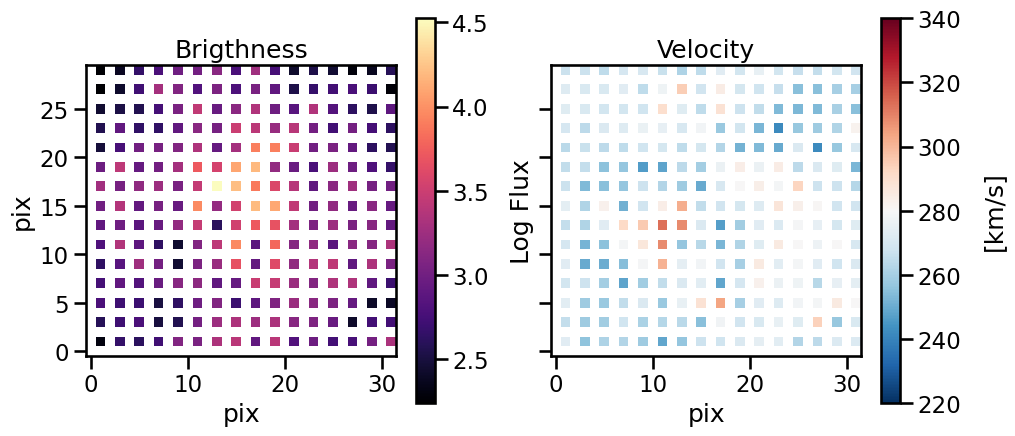

<Figure size 640x480 with 0 Axes>

In [11]:
fig, (ax, axx) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(11, 5),
)

imshow_kwds = dict(origin="lower", cmap="magma")
im = ax.imshow(np.log10(sb), **imshow_kwds)
cbar = fig.colorbar(im, ax=[ax])
cbar.set_label("Log Flux", rotation=90, labelpad=15)

imshow_kwds2 = dict(origin="lower", cmap="RdBu_r")
im = axx.imshow(vv,vmin=220,vmax=340, **imshow_kwds2)
cbar = fig.colorbar(im, ax=[axx])
cbar.set_label("[km/s]", rotation=90, labelpad=15)

ax.set_xlabel("pix")
ax.set_ylabel("pix")
axx.set_xlabel("pix")
ax.set_title("Brigthness")
axx.set_title("Velocity")

plt.show()

plt.savefig(name + '.jpg', bbox_inches='tight')

In [12]:
from astropy.wcs import WCS
from astropy.io import fits

# Read the spatial WCS from each moment extension.
with fits.open(fits_path) as hdul:
    wcs_sb = WCS(hdul["MOM0"].header).celestial
    wcs_vv = WCS(hdul["MOM1"].header).celestial

if not (wcs_sb.has_celestial and wcs_vv.has_celestial):
    raise ValueError("The moment extension headers lack celestial WCS.")

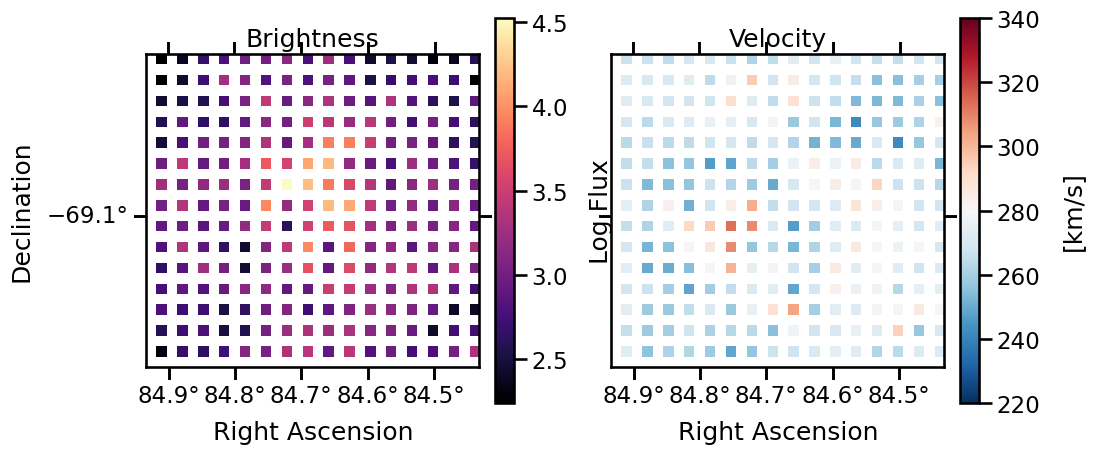

In [13]:
fig, (ax, axx) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(11, 5),
    subplot_kw={"projection": wcs_sb},
)

# Brightness
im = ax.imshow(np.log10(sb), origin="lower", cmap="magma")
cbar = fig.colorbar(im, ax=ax, fraction=0.1, pad=0.04)
cbar.set_label("Log Flux", rotation=90, labelpad=15)

# Velocity
im = axx.imshow(
    vv, vmin=220, vmax=340,
    origin="lower", cmap="RdBu_r",
)
cbar = fig.colorbar(im, ax=axx, fraction=0.1, pad=0.04)
cbar.set_label("[km/s]", rotation=90, labelpad=15)

for axis in (ax, axx):
    axis.coords[0].set_axislabel("Right Ascension")
    axis.coords[0].set_major_formatter("d.d")
    axis.coords[1].set_major_formatter("d.d")

ax.coords[1].set_axislabel("Declination")

# Show declination labels only on the left panel.
axx.coords[1].set_ticklabel_visible(False)
axx.coords[1].set_axislabel("")

ax.set_title("Brightness")
axx.set_title("Velocity")

fig.savefig(name + ".jpg", dpi=300, bbox_inches="tight")
plt.show()

# Structure function

In [14]:
# Keep NaNs in vv and sb for plotting.
valid = np.isfinite(vv) & np.isfinite(sb) & (sb > 0)

if np.count_nonzero(valid) < 2:
    raise ValueError("Fewer than two valid pixels remain.")

# Separate computational arrays:
# excluded pixels have finite placeholder velocities and zero weights.
vv_sf = np.where(valid, vv, np.nanmean(vv))
sb_sf = np.where(valid, sb, 0.0)

In [15]:
#rslt = strucfunc.strucfunc_numba_parallel(vv, wmap=sb, dlogr=0.05)

rslt = strucfunc.strucfunc_numba_parallel(
    vv_sf,
    wmap=sb_sf,
    dlogr=0.05,
    wmin_factor=0.0,
)

C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\FLAMES_30dor\FLAMES_regular_cube\py_modules\strucfunc.py:83: RuntimeWarning: invalid value encountered in divide
  'Unweighted B(r)': sf/nsf,
C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\FLAMES_30dor\FLAMES_regular_cube\py_modules\strucfunc.py:84: RuntimeWarning: invalid value encountered in divide
  'Weighted B(r)': wsf/weight}


In [16]:
rslt_ = pd.DataFrame(rslt)

In [17]:
#rslt["Unweighted mean velocity"] = np.mean(vv)
#rslt["Unweighted sigma^2"] = np.var(vv)
#v0w = rslt["Weighted mean velocity"] = np.average(vv, weights=sb)
#rslt["Weighted sigma^2"] = np.average((vv - v0w)**2, weights=sb)

In [18]:
v = vv[valid]
w = sb[valid]

rslt["Unweighted mean velocity"] = np.mean(v)
rslt["Unweighted sigma^2"] = np.var(v)

v0w = np.average(v, weights=w)
rslt["Weighted mean velocity"] = v0w
rslt["Weighted sigma^2"] = np.average((v - v0w)**2, weights=w)

# Build the dataframe AFTER adding the statistics.
rslt_ = pd.DataFrame(rslt)

In [19]:
#rslt_

In [20]:
b2    = rslt['Unweighted B(r)']
b2w   = rslt['Weighted B(r)']
e_b2  = b2  *.1
e_b2w = b2w  *.1

s     = 10**rslt['log10 r'] * pix * pc
e_s   = s  *.1
sig2  = rslt['Unweighted sigma^2']
sig2w = rslt['Weighted sigma^2']

sig   = sig2**0.5

In [21]:
b2w

array([         nan,          nan,          nan,          nan,
                nan,          nan, 139.69973512,          nan,
                nan, 283.46840019,          nan,          nan,
       267.57126575, 327.07356058,          nan, 354.32951312,
       314.75832143, 337.73742607, 374.75742122, 369.43187358,
       296.91428664, 287.49817156, 262.80970833, 264.193392  ,
       247.60513154, 250.50076925, 268.10496819, 225.91192953,
       164.04625894, 107.42898344,  82.3122299 ,  51.52663797])

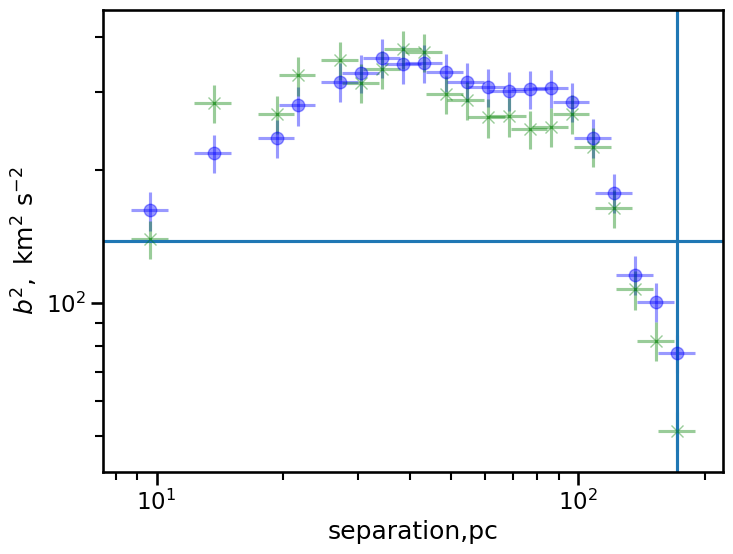

In [22]:
r0    = np.interp(sig2, b2[1:35], s[1:35])
ra = r0
m     = 1
noise = 0

rgrid = np.linspace(s[0], s[:-1])

fig, ax = plt.subplots(figsize=(8, 6))

ax.errorbar(s, b2, yerr=e_b2, xerr=e_s, fmt='o', alpha=0.4,color="blue")
ax.errorbar(s, b2w, yerr=e_b2w, xerr=e_s, fmt='x', alpha=0.4,color="green")

ax.axhline(sig2, ls='-')
ax.axvline(r0, ls='-')

#ax.plot(rgrid, bfunc.bfunc00s(rgrid, r0, sig2, m), color="0.8")
#ax.plot(rgrid, bfunc.bfunc03s(rgrid, r0, sig2, m, s0, noise), color="black")
#ax.plot(rgrid, bfunc.bfunc04s(rgrid, r0, sig2, m, s0, noise, box_size), color="black")


ax.set(xscale='log', yscale='log', 
       xlabel='separation,pc',
       ylabel=r'$b^2,\ \mathrm{km^2\ s^{-2}}$'
      )
None

plt.show()



# Export

In [23]:
from astropy.table import Table


df =  rslt_.copy()

# Flatten MultiIndex columns like ('s','count') -> "s_count"
if isinstance(df.columns, pd.MultiIndex):
    df.columns = ["_".join(map(str, col)).strip() for col in df.columns.to_flat_index()]
else:
    df.columns = [str(c) for c in df.columns]

# (Optional) drop index to avoid it becoming an extra column
df = df.reset_index(drop=True)

t = Table.from_pandas(df)
new_hdu = fits.BinTableHDU(t, name="TABLE")

In [25]:
# Remove ALL previous TABLE extensions, preserving other HDUs.
with fits.open(fits_path) as hdul:
    hdus = [
        h.copy()
        for h in hdul
        if h.name.upper() != "TABLE"
    ]

new_hdu.header["MASKTYPE"] = "CHECKER"
new_hdu.header["PHASC"] = int(col_phase)
new_hdu.header["PHASR"] = int(row_phase)
new_hdu.header["NVALID"] = int(valid.sum())
new_hdu.header["WMINFAC"] = 0.0

hdus.append(new_hdu)

with fits.HDUList(hdus) as output:
    output.writeto(fits_path, overwrite=True)

# Verify that exactly one table exists and matches this run.
with fits.open(fits_path) as check:
    assert sum(h.name.upper() == "TABLE" for h in check) == 1

    for column in ("Unweighted B(r)", "Weighted B(r)"):
        np.testing.assert_allclose(
            check["TABLE"].data[column],
            np.asarray(rslt[column]),
            equal_nan=True,
        )

print("Current structure-function table saved:", Path(fits_path).resolve())

Current structure-function table saved: C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\FLAMES_30dor\FLAMES_regular_cube\fits_ready\FLAMES-30Dor-Ha-bin0-grid_1.fits


In [26]:
with fits.open(fits_path, mode="readonly") as hdul:
    hdus = [h.copy() for h in hdul]   # copy existing HDUs

hdus.append(new_hdu)
fits.HDUList(hdus).writeto(fits_path, overwrite=True)

In [27]:
# Test import

from astropy.table import Table
t = Table.read(fits_path, hdu="TABLE")
df_loaded = t.to_pandas()
df_loaded


,log10 r,Sum dv^2,Sum weights,Sum w * dv^2,N pairs,Unweighted B(r),Weighted B(r),Unweighted mean velocity,Unweighted sigma^2,Weighted mean velocity,Weighted sigma^2
0,0.00,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN,268.904511,137.897031,266.900255,139.937994
1,0.05,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN,268.904511,137.897031,266.900255,139.937994
2,0.10,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN,268.904511,137.897031,266.900255,139.937994
3,0.15,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN,268.904511,137.897031,266.900255,139.937994
4,0.20,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN,268.904511,137.897031,266.900255,139.937994
5,0.25,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN,268.904511,137.897031,266.900255,139.937994
6,0.30,36454.963505,1.928443e+09,2.694030e+11,225,162.022060,139.699735,268.904511,137.897031,266.900255,139.937994
7,0.35,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN,268.904511,137.897031,266.900255,139.937994
8,0.40,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN,268.904511,137.897031,266.900255,139.937994
9,0.45,91741.868505,3.455048e+09,9.793969e+11,420,218.433020,283.468400,268.904511,137.897031,266.900255,139.937994


In [28]:
print("--- %s seconds ---" % (time.time()-start_time))

--- 121.17647695541382 seconds ---
